In [3]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

In [5]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [10]:
df["payment"] = df["payment"].fillna(df["payment"].mode()[0])

df = df.dropna(subset=["pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"])

print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


In [6]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      

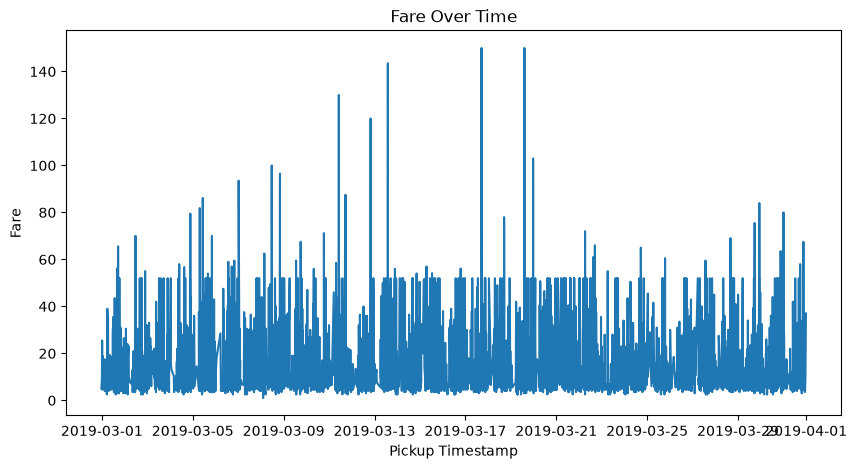

In [4]:
df["pickup"] = pd.to_datetime(df["pickup"])
df = df.sort_values("pickup")
plt.figure(figsize=(10,5))
plt.plot(df["pickup"], df["fare"])
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")
plt.show()

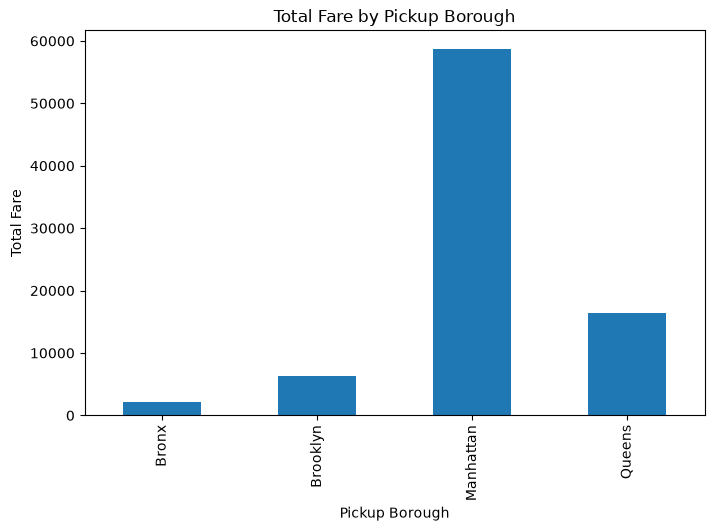

In [5]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()
borough_fare.plot(kind="bar", figsize=(8,5))
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")
plt.show()

In [8]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("taxis")

df["payment"] = df["payment"].fillna(df["payment"].mode()[0])
df = df.dropna(subset=["pickup_zone", "dropoff_zone", "pickup_borough", "dropoff_borough"])

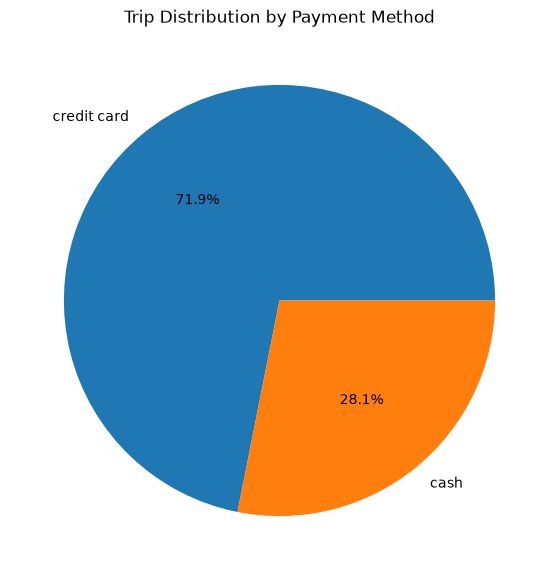

In [9]:
payment_counts = df["payment"].value_counts()

payment_counts.plot(kind="pie", autopct="%1.1f%%", figsize=(7,7))

plt.title("Trip Distribution by Payment Method")
plt.ylabel("")

plt.show()

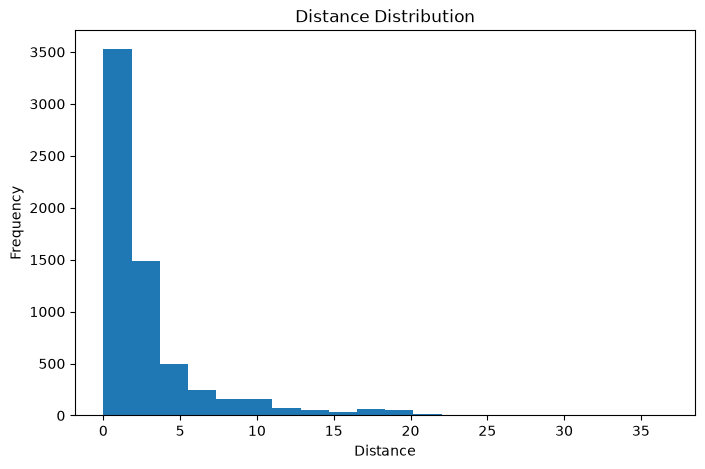

In [10]:
plt.figure(figsize=(8,5))

plt.hist(df["distance"], bins=20)

plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.title("Distance Distribution")

plt.show()

<Figure size 800x500 with 0 Axes>

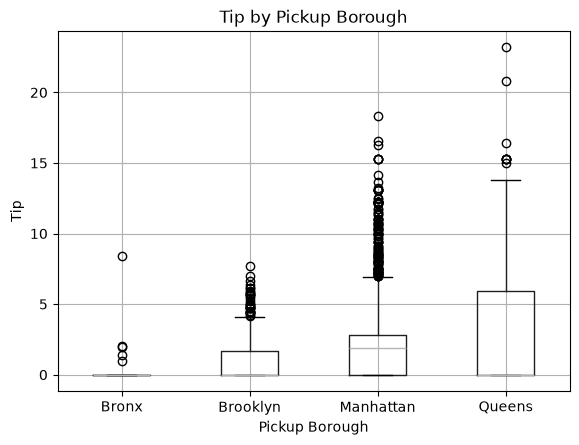

In [11]:
plt.figure(figsize=(8,5))
df.boxplot(column="tip", by="pickup_borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")
plt.title("Tip by Pickup Borough")
plt.suptitle("")
plt.show()

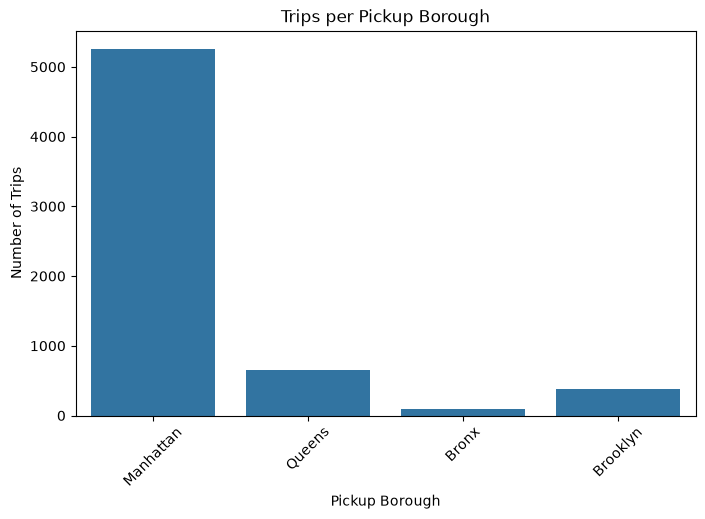

In [12]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="pickup_borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Trips per Pickup Borough")
plt.xticks(rotation=45)
plt.show()

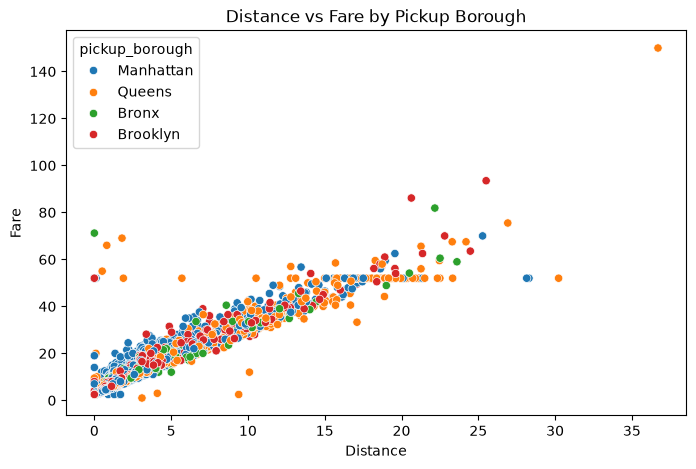

In [13]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Distance vs Fare by Pickup Borough")
plt.show()

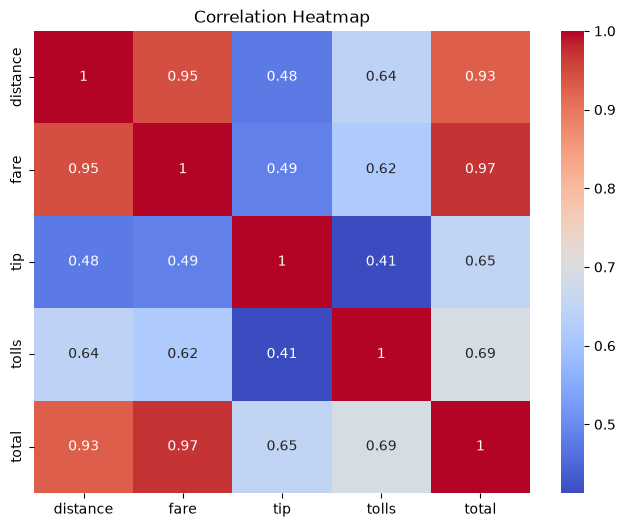

In [14]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

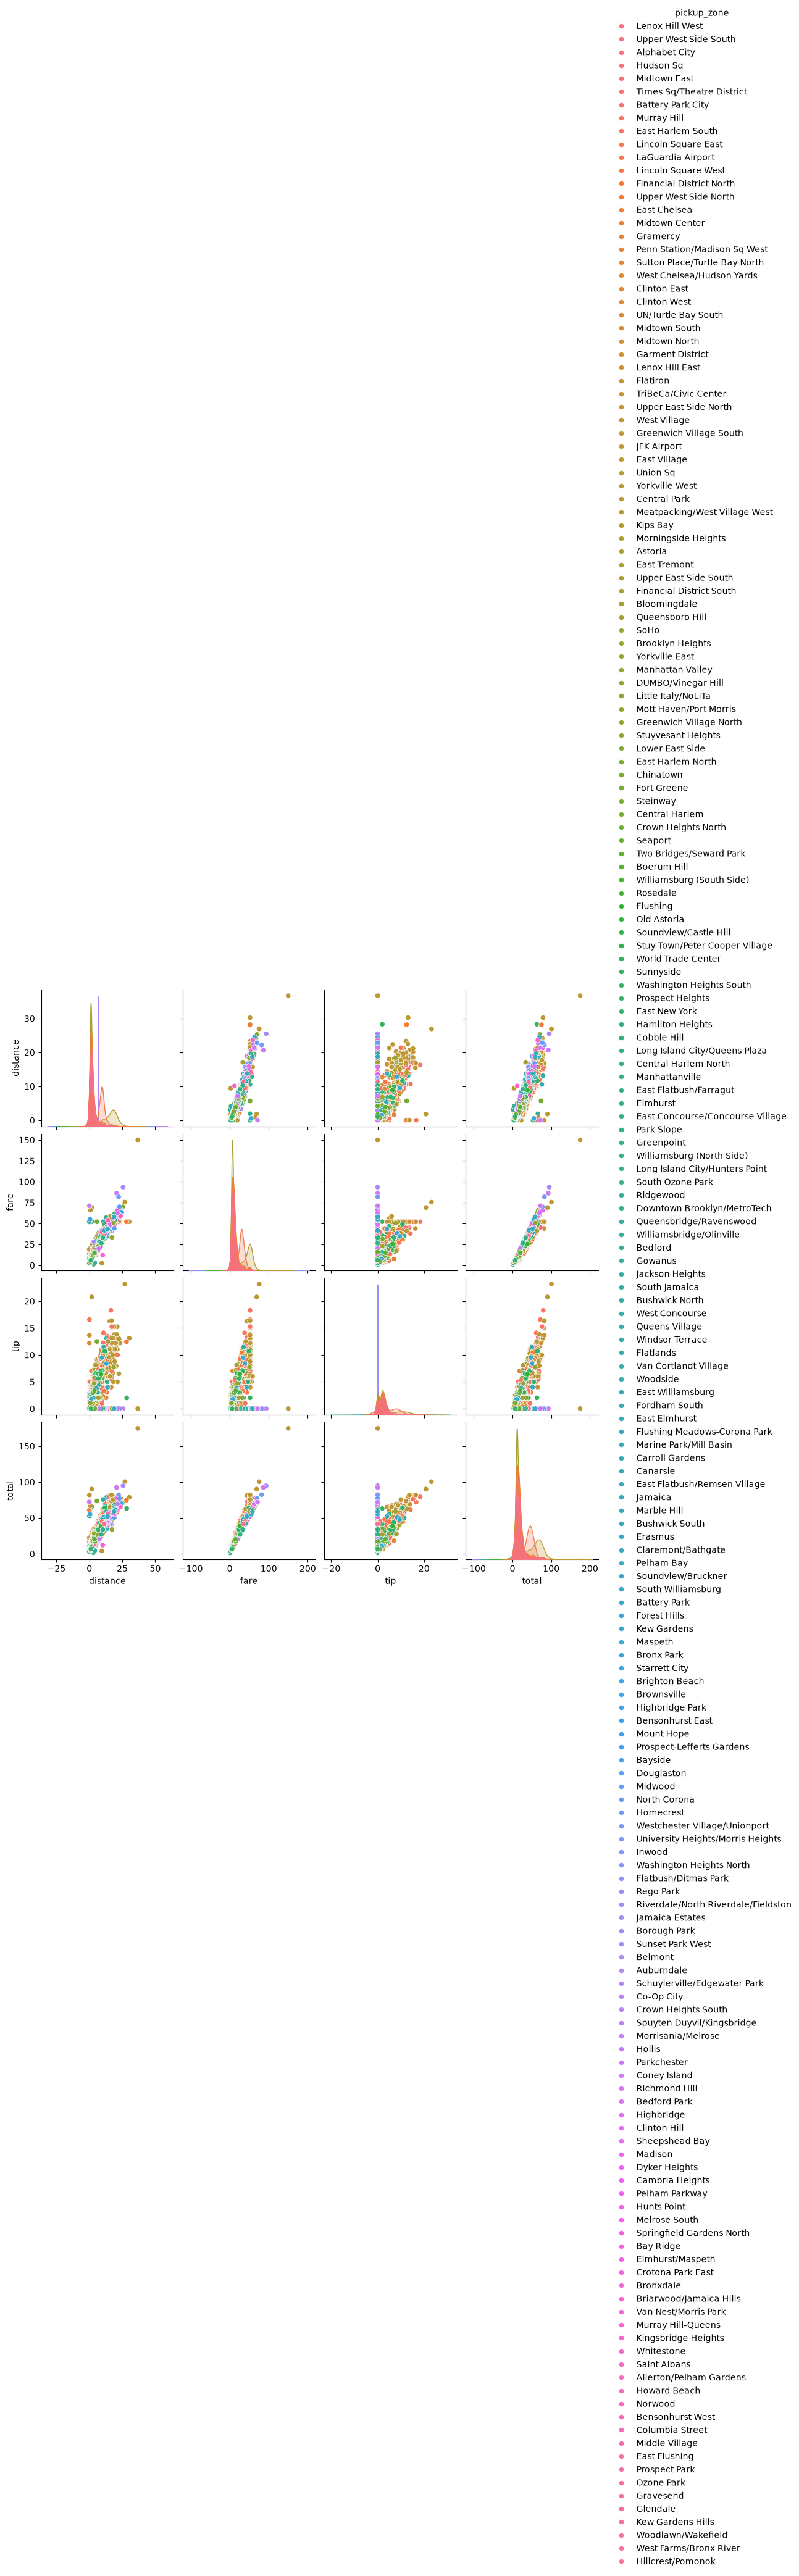

In [15]:
sns.pairplot(
    df[["distance", "fare", "tip", "total", "pickup_zone"]],
    hue="pickup_zone"
)
plt.show()

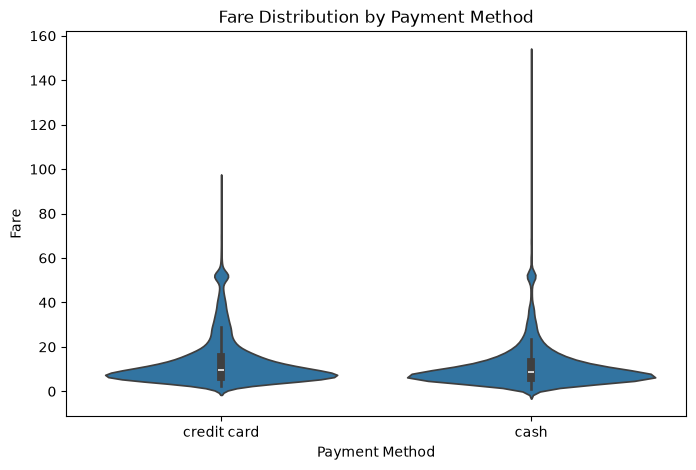

In [16]:
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x="payment", y="fare")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution by Payment Method")
plt.show()